# 🧪 LAB: Implement an autoencoder with `PyTorch`

In this lab, you will implement and explore autoencoders using the MNIST dataset. The goal is to understand how autoencoders learn compressed representations of data, and how these representations compare with classical methods like PCA.

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Laine Goldmacher, Max Magrill, Ashley Qin"

## 1. Theoretical Background Reflection (10 points)

Read *Michelucci (2022)*: [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898) — focus on the following sections:  
- 1. Introduction
- 2.1, 2.2, and 2.3
- Skim Section 3 on applications  

Then answer briefly:

1. What is the main idea behind an autoencoder?  
2. What is the role of the bottleneck layer?  
3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.  
4. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?


1. Goal: learning to reconstruct the input observations xi with the lowest error possible. An autoencoder is a type of algorithm with the primary purpose of learning an "informative" representation of the data that can be used for different applications by learning to reconstruct a set of input observations well enough. The autoencoder has three main components: an encoder, a latent feature representation, and a decoder. The encoder and decoder are simply functions, while the latent feature representation is typically a tensor of real numbers. Generally speaking, we want the autoencoder to reconstruct the input well enough. Still, at the same time, it should create a latent representation that is useful and meaningful. In most typical architectures, the encoder and the decoder are neural networks. 
2. Adding a "bottleneck" is achieved by making the latent feature’s dimensionality lower than the input’s. An autoencoder with a middle layer smaller than the input dimensions (this is the bottleneck) can be used to extract the essential features of an input dataset creating a learned representation of the inputs given by the function g(xi). This bottleneck can be used to perform dimensionality reduction.
3. Some of the applications of autoencoders are dimensionality reduction, classification, anomaly detection, and denoising. The encoder part of the autoencoder (once trained) naturally performs dimension reduction, producing q real numbers. Classification performed by an autoencoder also sees high accuracy and faster running time. Autoencoders are also often used for anomaly detection on many different datasets. Finally, denoising autoencoders are developed to auto-correct errors (noise) in the input observations. 
4. Compared to PCA, the autoencoder has the benefit of being able to deal with a very big amount of data efficiently since its training can be done with mini-batches. However, PCA, one of the most used dimensionality reduction algorithms, needs to do its calculations using the entire dataset. This makes PCA a lot less computationally efficient. PCA is an algorithm that projects a dataset on the eigenvectors of its covariance matrix, thus providing a linear transformation of the features. Autoencoders are more flexible and consider non-linear transformations of the features. The default PCA method is not computationally efficient, and the algorithm does not scale up with increasing dataset size. Therefore, we would expect the autoencoder's representation to occur more quickly than PCA for dimensionality reduction. Additionally, we would expect more accurate results from the autoencoder when there are nonlinear relationships in the data because PCA only performs linear transformations of features.  

## 2. Prepare the Data (10 points)

Given the below dataset:

- Normalize **each** image (i.e., separately) so its values are between 0 and 1. Remember our first-week discussions of fixed and fitted transformations.
- Visualize a few random digits to confirm everything worked as expected.
- Split the dataset into fitting, tuning and reporting sets (70%, 15%, 15%).
- Wrap each data splitting as `DataLoader` object with a batch size of 128. Call them `fitting_loader`, `tuning_loader` and `reporting_loader`, respectively.

In [13]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1, as_frame=False, n_retries=5, delay=2)
X, y = mnist.data, mnist.target.astype(int)

In [14]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader, random_split

X = X.astype(np.float32)
X_min = X.min(axis=1, keepdims=True)
X_max = X.max(axis=1, keepdims=True)
X = (X - X_min) / np.maximum(X_max - X_min, 1e-8)

print(X.shape, X.min(), X.max())

(70000, 784) 0.0 1.0


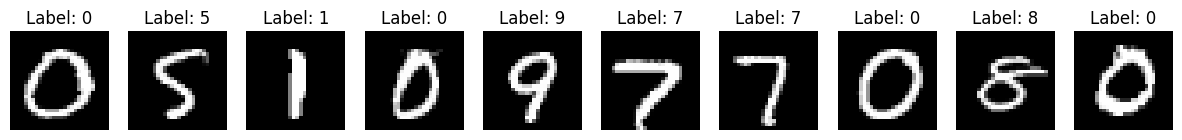

In [15]:
rng = np.random.default_rng(0)
idx = rng.choice(len(X), size=10, replace=False)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for ax, i in zip(axes, idx):
    ax.imshow(X[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")
plt.show()

In [16]:
dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))

generator = torch.Generator().manual_seed(42)
fitting_set, tuning_set, reporting_set = random_split(dataset, [0.70, 0.15, 0.15], generator=generator)

fitting_loader = DataLoader(fitting_set, batch_size=128, shuffle=True)
tuning_loader = DataLoader(tuning_set, batch_size=128, shuffle=False)
reporting_loader = DataLoader(reporting_set, batch_size=128, shuffle=False)

print(len(fitting_set), len(tuning_set), len(reporting_set))

49000 10500 10500


## 3. Autoencoder

In this section, you will build and train an **autoencoder** to reconstruct the provided data.

Your model will include three layers in both the encoder and decoder:

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Implementation (30 points)

Follow the skeleton provided below and fill in the missing parts (`#TODO`). 

Follow these restrictions:

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. Determine the appropriate order for these components based on what we discussed in class. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [17]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        # ENCODING PART: 784 -> 128 -> 64 -> 2
        encoder_list = [
            nn.Linear(X.shape[1], 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(64, 2)
        ]
        self.encoder_list = nn.ModuleList(encoder_list)
        
        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            nn.Linear(2, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(64, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, X.shape[1]),
            nn.Sigmoid()
        ]
        self.decoder_list = nn.ModuleList(decoder_list)
        
    def forward(self, X):
        for layer in self.encoder_list:
            X = layer(X)
        for layer in self.decoder_list:
            X = layer(X)
        output = X
        return output

### 3.2 Training (15 points)

Follow the skeleton provided below and fill in the missing parts to train your model (`#TODO`). As you can see, training includes EarlyStopping, which I give you already for your convenience :-). After you have filled these missing parts, uncomment the provided piece of code with the function for training (`train_autoencoder`) your model and execute it.

But, **BEFORE** that, discuss with your mates and provide elaborated answers to the following:

- Why do you think the output layer of the autoencoder above uses a Sigmoid activation?
- Based on this, which cost function is most appropriate for this task? Justify your choice.

YOUR RESPONSES HERE. YOU MAY USE MORE CELLS THAN THIS ONE

Once you have discussed and agreed on the reasoning above, proceed to complete the skeleton (`#TODO`) and train the model.


In [18]:
from torch import optim

# TODO: Replace None to instantiate the autoencoder
model = Autoencoder()  

# TODO: Replace None with the appropriate Loss function from 'torch.nn'
# Hint: we are reconstructing continuous pixel values in [0,1]
criterion = nn.BCELoss()

# TODO: Replace None with Adam optimizer. 
# Use learning rate of 0.001 and an L2 regularization via weight_decay of 1e-5
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)  

In [19]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    # Initialize the early stopping object
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            # --- Implement the standard training steps ---
            
            outputs = model(X_batch)             
            cost = criterion(outputs, X_batch)   
            cost.backward()                     
            optimizer.step()                    
            optimizer.zero_grad()                
            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        # --- Tuning phase ---
        model.eval()
        tuning_cost = 0.0
        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                outputs = model(X_batch)   
                cost = criterion(outputs, X_batch)   
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        # --- Save metrics ---
        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        # --- Early stopping check ---
        early_stopping(tuning_cost, model)
        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    return model, history


Once the missing parts have been filled, uncomment the piece of code below and execute it to train your model (it may take a bit to complete the training, which is totally normal).

In [20]:
model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

Epoch [1/50]  Fitting Cost: 0.25858  Tuning Cost: 0.21024
Epoch [2/50]  Fitting Cost: 0.21161  Tuning Cost: 0.20141
Epoch [3/50]  Fitting Cost: 0.20695  Tuning Cost: 0.19814
Epoch [4/50]  Fitting Cost: 0.20487  Tuning Cost: 0.19637
Epoch [5/50]  Fitting Cost: 0.20375  Tuning Cost: 0.19554
Epoch [6/50]  Fitting Cost: 0.20295  Tuning Cost: 0.19444
Epoch [7/50]  Fitting Cost: 0.20237  Tuning Cost: 0.19388
Epoch [8/50]  Fitting Cost: 0.20213  Tuning Cost: 0.19318
Epoch [9/50]  Fitting Cost: 0.20163  Tuning Cost: 0.19297
Epoch [10/50]  Fitting Cost: 0.20121  Tuning Cost: 0.19227
Epoch [11/50]  Fitting Cost: 0.20107  Tuning Cost: 0.19209
Epoch [12/50]  Fitting Cost: 0.20070  Tuning Cost: 0.19189
Epoch [13/50]  Fitting Cost: 0.20040  Tuning Cost: 0.19140
Epoch [14/50]  Fitting Cost: 0.20018  Tuning Cost: 0.19156
Epoch [15/50]  Fitting Cost: 0.19998  Tuning Cost: 0.19145
Epoch [16/50]  Fitting Cost: 0.19988  Tuning Cost: 0.19129
Epoch [17/50]  Fitting Cost: 0.19977  Tuning Cost: 0.19148
Epoch 

### 3.3 Reconstruct (5 points)

Once you have trained the model: 

1. Visualize several reconstructed digits from the reporting set.  
2. Compare them with the corresponding original input digits. Was the reconstruction good? 

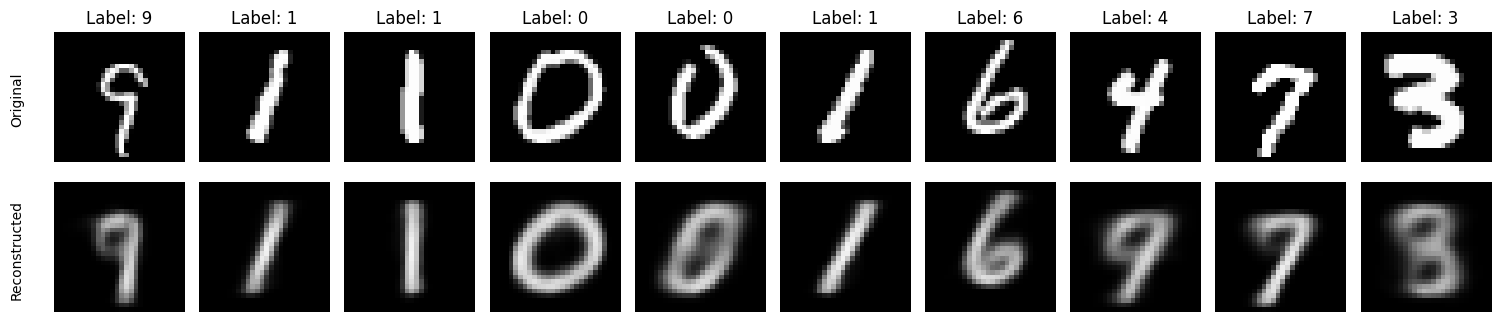

In [26]:
model.eval() 
with torch.no_grad():
    X_batch, y_batch = next(iter(reporting_loader))
    reconstructed = model(X_batch)

n = 10
fig, axes = plt.subplots(2, n, figsize=(15, 3.5))
for i in range(n):
    axes[0, i].imshow(X_batch[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"Label: {y_batch[i].item()}")
    axes[0, i].axis("off")
    axes[1, i].imshow(reconstructed[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axes[1, i].axis("off")

axes[0, 0].text(-10, 14, "Original", rotation=90, va="center")
axes[1, 0].text(-10, 14, "Reconstructed", rotation=90, va="center")
plt.tight_layout()
plt.show()

The reconstruction was pretty good, as most numbers are recognizable. However, the 4 looks more like a 9, and the 3 could easily be confused for an 8. In addition, the reconstructions are quite blurry. Though, this was a pretty good reconstruction and the shapes themselves were well retained.

## 4. Visualize the Learned Representations (15 points)

Here you will explore the latent representations learned by your autoencoder.

1. Complete `extract_latent_features` to extract the latent (bottleneck) features and their corresponding labels, given a trained model.  
   Apply this function to the reporting set using the provided code. This should give you the transformed reporting set with the dimensions of the bottleneck (2).
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [32]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            encoded = X_batch
            for layer in model.encoder_list: 
                encoded = layer(encoded)
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

Once the missing parts above have been filled, uncomment the piece of code below and execute it to extract the latent features

In [33]:
latents_autoencoder, labels = extract_latent_features(model, reporting_loader)

In [36]:
print(latents_autoencoder)
print(labels)

[[-1.0633212  -1.1631467 ]
 [-1.04716     0.45668083]
 [-1.3637159  -0.34782124]
 ...
 [ 0.7435919  -0.5850158 ]
 [-0.4669337  -0.41973513]
 [-0.01981384 -0.82487744]]
[9 1 1 ... 8 9 7]


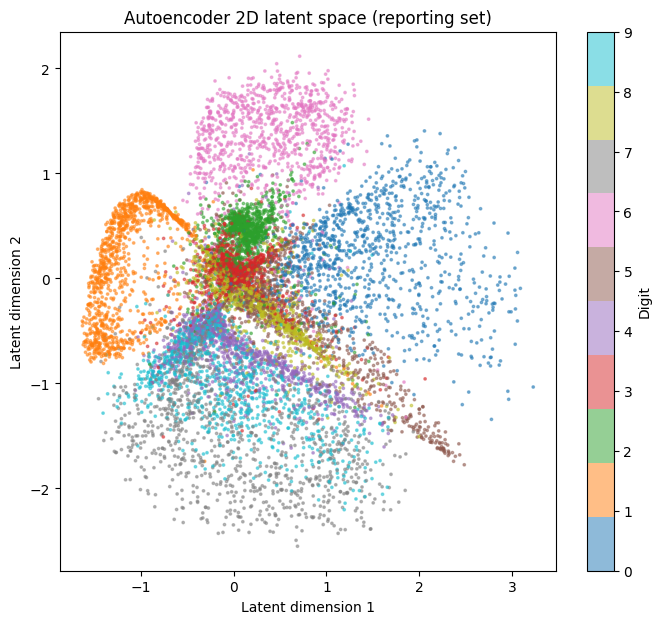

In [47]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 7))
scatter = plt.scatter(latents_autoencoder[:, 0], latents_autoencoder[:, 1], c=labels, cmap="tab10", s=3, alpha=0.5)
plt.colorbar(scatter, ticks=range(10), label="Digit")
plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.title("Autoencoder 2D latent space (reporting set)")
plt.show()

## 5. Compare with PCA (10 points)

Here you will compare the latent representations learned by your autoencoder with those obtained using a PCA.

1. Apply a PCA to the reporting set (without using the autoencoder) to reduce the data to the same dimensionality as your bottleneck (2 dimensions). Obviously, first use the rest of the data to learn these two components.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA) and briefly discuss the differences (if any) you observe.

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE